# COS802 Project — Housing Price Prediction
## Notebook 05: Final Evaluation, Interpretability and Error Analysis

This notebook completes the modelling study.

The development-only experiments selected **XGBoost with engineered features** using mean cross-validation RMSE. This notebook now:

1. freezes that configuration;
2. fits it once on all 2,344 development properties;
3. evaluates it once on the locked 586-property test set;
4. compares final test performance with simple reference baselines;
5. performs residual and subgroup error analysis;
6. uses XGBoost feature importance and SHAP to address RQ4.

The held-out test set is used for final evaluation only and is not used to retune the model.


In [1]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
from pathlib import Path
import sys
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    from xgboost import XGBRegressor
except ImportError:
    !pip -q install xgboost
    from xgboost import XGBRegressor

try:
    import shap
except ImportError:
    !pip -q install shap
    import shap


# Canonical reusable project code
PROJECT_DIR = Path("/content/drive/MyDrive/MIT BIG DATA SCIENCE/COS802_PROJECT")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.config import SEED, TARGET, IDENTIFIERS, DATA_FILE, PROCESSED_DIR, SPLITS_DIR, FIGURES_DIR
from src.features import (
    STRUCTURAL_NONE_COLS, ENGINEERED_FEATURES, apply_structural_absence,
    AmesFeatureEngineer, validate_engineered_features, validate_feature_alignment,
)
from src.preprocessing import ORDINAL_CATEGORY_MAP, build_preprocessor
from src.evaluation import regression_metrics

SEED=16153970
np.random.seed(SEED)

PROJECT_DIR=Path("/content/drive/MyDrive/MIT BIG DATA SCIENCE/COS802_PROJECT")
RAW_DIR=PROJECT_DIR/"data"/"raw"
PROCESSED_DIR=PROJECT_DIR/"data"/"processed"
SPLITS_DIR=PROJECT_DIR/"data"/"splits"
FIGURES_DIR=PROJECT_DIR/"figures"

df=pd.read_csv(RAW_DIR/"AmesHousing.txt",sep="\t")
split_membership=pd.read_csv(SPLITS_DIR/"train_test_split.csv")
selected_cfg=pd.read_csv(PROCESSED_DIR/"development_selected_configuration.csv")

print("Dataset:",df.shape)
display(selected_cfg)


Dataset: (2930, 82)


,Model,Representation,Config,Params,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd
0,XGBoost,Engineered,4,"{'n_estimators': 400, 'max_depth': 4, 'learnin...",13516.278346,1230.579636,22195.446387,3521.744596,0.921664,0.017161


## 1. Restore development and locked test sets


In [3]:
TARGET="SalePrice"; IDENTIFIERS=["Order","PID"]

dev_idx=split_membership.loc[
    split_membership["split"]=="development","row_index"
].astype(int).to_numpy()
test_idx=split_membership.loc[
    split_membership["split"]=="test","row_index"
].astype(int).to_numpy()

dev_df=df.loc[dev_idx].copy()
test_df=df.loc[test_idx].copy()

X_dev_raw=dev_df.drop(columns=[TARGET]+IDENTIFIERS)
y_dev=dev_df[TARGET].astype(float).copy()
X_test_raw=test_df.drop(columns=[TARGET]+IDENTIFIERS)
y_test=test_df[TARGET].astype(float).copy()

assert len(dev_df)==2344
assert len(test_df)==586
assert set(dev_idx).isdisjoint(set(test_idx))

print("Development:",X_dev_raw.shape)
print("Test:",X_test_raw.shape)


Development: (2344, 79)
Test: (586, 79)


## 2. Reproduce the frozen engineered representation and preprocessing


In [4]:
X_dev = AmesFeatureEngineer().fit_transform(X_dev_raw)
X_test = AmesFeatureEngineer().transform(X_test_raw)
validate_engineered_features(X_dev)
validate_engineered_features(X_test)
validate_feature_alignment(X_dev, X_test)
print("Engineered development:", X_dev.shape)
print("Engineered test:", X_test.shape)


Engineered development: (2344, 89)
Engineered test: (586, 89)


In [5]:
# Preprocessing is implemented centrally in src/preprocessing.py.
print("Using canonical build_preprocessor from src.preprocessing")


Using canonical build_preprocessor from src.preprocessing


## 3. Freeze the development-selected XGBoost configuration

The parameters are read from Notebook 04's saved selection rather than chosen from test performance.


In [6]:
row=selected_cfg.iloc[0]
assert row["Model"]=="XGBoost"
assert row["Representation"]=="Engineered"

params=ast.literal_eval(row["Params"])
print("Frozen parameters:",params)

final_model=Pipeline([
    ("preprocessor",build_preprocessor(X_dev)),
    ("model",XGBRegressor(
        **params,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=SEED,
        n_jobs=-1
    ))
])

final_model.fit(X_dev,y_dev)
test_pred=np.maximum(final_model.predict(X_test),0)

print("Final model fitted on all development data.")


Frozen parameters: {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_lambda': 5.0}
Final model fitted on all development data.


## 4. One-time held-out test evaluation

These are the primary final generalisation results. No further hyperparameter or feature selection should be made from these values.


In [7]:
final_metrics=regression_metrics(y_test,test_pred)
print(f"Test MAE:  ${final_metrics['MAE']:,.2f}")
print(f"Test RMSE: ${final_metrics['RMSE']:,.2f}")
print(f"Test R²:    {final_metrics['R2']:.4f}")

pd.DataFrame([{"Model":"XGBoost | Engineered",**final_metrics}]).to_csv(
    PROCESSED_DIR/"final_test_metrics.csv",index=False
)


Test MAE:  $13,885.15
Test RMSE: $25,354.31
Test R²:    0.8999


## 4.1 Bootstrap uncertainty for final test metrics

Point estimates alone do not show sampling uncertainty. The following paired non-parametric bootstrap resamples the **already frozen test predictions** 5,000 times and reports 95% confidence intervals for MAE, RMSE and R².

This is uncertainty analysis only: it does not alter the model, features or hyperparameters.


In [8]:
def bootstrap_intervals(y_true, y_pred, n_boot=5000, seed=SEED):
    y_true=np.asarray(y_true); y_pred=np.asarray(y_pred)
    rng=np.random.default_rng(seed)
    rows=[]
    n=len(y_true)
    for _ in range(n_boot):
        idx=rng.integers(0,n,n)
        rows.append(regression_metrics(y_true[idx],y_pred[idx]))
    b=pd.DataFrame(rows)
    ci=[]
    for m in ["MAE","RMSE","R2"]:
        lo,hi=b[m].quantile([0.025,0.975])
        ci.append({"Metric":m,"Estimate":final_metrics[m],"CI_Lower":lo,"CI_Upper":hi})
    return pd.DataFrame(ci)

bootstrap_ci=bootstrap_intervals(y_test,test_pred)
display(bootstrap_ci.round(3))
bootstrap_ci.to_csv(PROCESSED_DIR/"final_test_bootstrap_95ci.csv",index=False)

,Metric,Estimate,CI_Lower,CI_Upper
0,MAE,13885.154,12372.182,15772.309
1,RMSE,25354.315,18165.453,34407.447
2,R2,0.900,0.840,0.941


## 5. Final reference comparison

The mean-price predictor is fitted using the development target only. Ridge is included as the learned linear reference using its original feature representation and raw target, consistent with the baseline experiment.

These test results are reported for context; the selected XGBoost configuration is not changed after seeing them.


In [9]:
# Naive reference
mean_pred=np.repeat(y_dev.mean(),len(y_test))
mean_metrics=regression_metrics(y_test,mean_pred)

# Ridge original/raw reference
X_dev_original=apply_structural_absence(X_dev_raw)
X_test_original=apply_structural_absence(X_test_raw)

def ridge_preprocessor(X):
    num=X.select_dtypes(include=np.number).columns.tolist()
    cat=X.select_dtypes(exclude=np.number).columns.tolist()
    ordc=[c for c in ORDINAL_CATEGORY_MAP if c in cat]
    nom=[c for c in cat if c not in ordc]
    from sklearn.preprocessing import StandardScaler
    return ColumnTransformer([
      ("numeric",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),num),
      ("ordinal",Pipeline([
          ("imputer",SimpleImputer(strategy="most_frequent")),
          ("ordinal",OrdinalEncoder(categories=[ORDINAL_CATEGORY_MAP[c] for c in ordc],
                                    handle_unknown="use_encoded_value",unknown_value=-1))
      ]),ordc),
      ("nominal",Pipeline([
          ("imputer",SimpleImputer(strategy="most_frequent")),
          ("onehot",OneHotEncoder(handle_unknown="ignore"))
      ]),nom)
    ])

ridge=Pipeline([
    ("preprocessor",ridge_preprocessor(X_dev_original)),
    ("model",Ridge(alpha=10.0))
])
ridge.fit(X_dev_original,y_dev)
ridge_pred=np.maximum(ridge.predict(X_test_original),0)
ridge_metrics=regression_metrics(y_test,ridge_pred)

test_comparison=pd.DataFrame([
    {"Model":"Naive mean",**mean_metrics},
    {"Model":"Ridge | Original | Raw",**ridge_metrics},
    {"Model":"XGBoost | Engineered",**final_metrics}
]).sort_values("RMSE")

display(test_comparison.round(3))
test_comparison.to_csv(PROCESSED_DIR/"final_test_model_comparison.csv",index=False)


,Model,MAE,RMSE,R2
2,XGBoost | Engineered,13885.154,25354.315,0.900
1,Ridge | Original | Raw,17237.788,30911.519,0.851
0,Naive mean,58561.721,80166.887,-0.000


## 6. Actual versus predicted prices


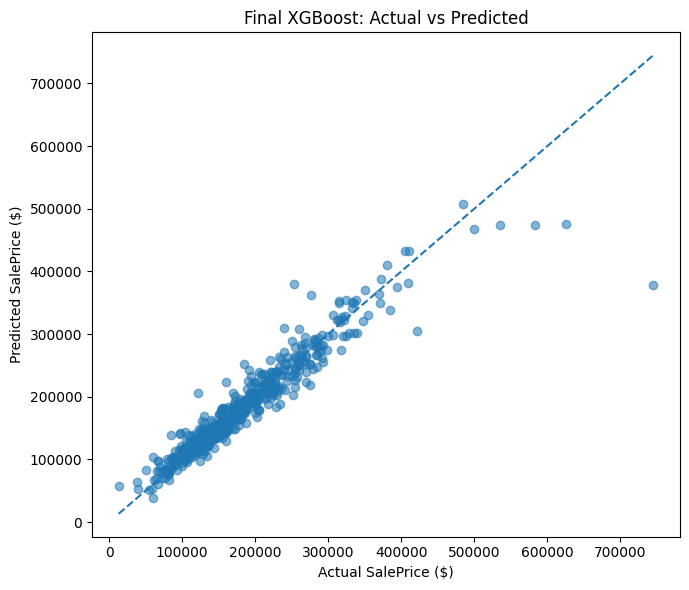

In [10]:
plt.figure(figsize=(7,6))
plt.scatter(y_test,test_pred,alpha=0.55)
lo=min(y_test.min(),test_pred.min()); hi=max(y_test.max(),test_pred.max())
plt.plot([lo,hi],[lo,hi],"--")
plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Predicted SalePrice ($)")
plt.title("Final XGBoost: Actual vs Predicted")
plt.tight_layout()
plt.savefig(FIGURES_DIR/"final_actual_vs_predicted.png",dpi=300,bbox_inches="tight")
plt.show()


## 7. Residual analysis

Residual is defined as `actual - predicted`. Positive residuals therefore indicate **underprediction**, while negative residuals indicate **overprediction**.


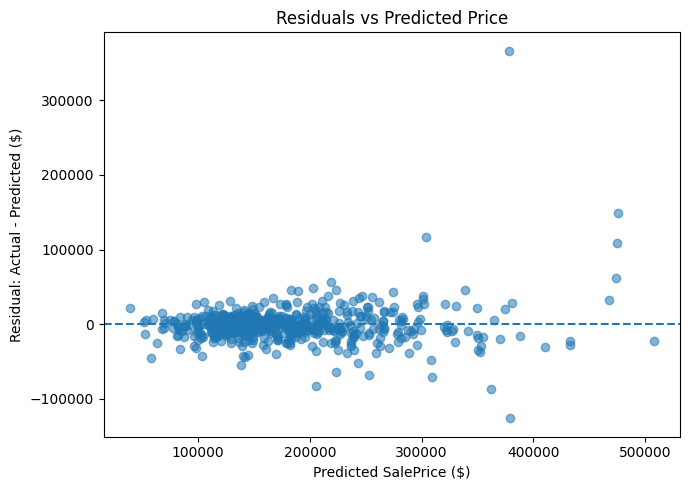

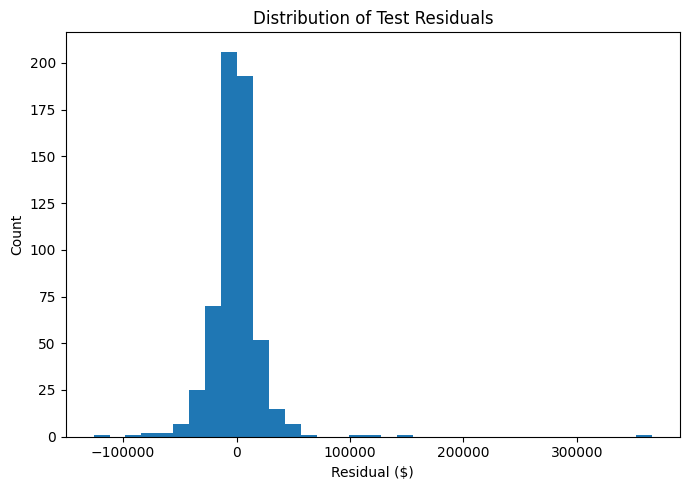

Mean residual: $-535.09
Median residual: $-535.23


In [11]:
residuals=y_test.to_numpy()-test_pred
abs_error=np.abs(residuals)

plt.figure(figsize=(7,5))
plt.scatter(test_pred,residuals,alpha=0.55)
plt.axhline(0,linestyle="--")
plt.xlabel("Predicted SalePrice ($)")
plt.ylabel("Residual: Actual - Predicted ($)")
plt.title("Residuals vs Predicted Price")
plt.tight_layout()
plt.savefig(FIGURES_DIR/"final_residuals_vs_predicted.png",dpi=300,bbox_inches="tight")
plt.show()

plt.figure(figsize=(7,5))
plt.hist(residuals,bins=35)
plt.xlabel("Residual ($)")
plt.ylabel("Count")
plt.title("Distribution of Test Residuals")
plt.tight_layout()
plt.savefig(FIGURES_DIR/"final_residual_distribution.png",dpi=300,bbox_inches="tight")
plt.show()

print("Mean residual:",f"${residuals.mean():,.2f}")
print("Median residual:",f"${np.median(residuals):,.2f}")


## 8. Error by actual-price range

The test properties are grouped into quartiles based on the **test-set SalePrice distribution solely for post-hoc error analysis**. These groups are not used to tune or select the model.


In [12]:
error_df=pd.DataFrame({
    "Actual":y_test.to_numpy(),
    "Predicted":test_pred,
    "Residual":residuals,
    "AbsoluteError":abs_error
},index=y_test.index)

error_df["PriceQuartile"]=pd.qcut(
    error_df["Actual"],q=4,
    labels=["Q1 lowest","Q2","Q3","Q4 highest"]
)

quartile_errors=error_df.groupby("PriceQuartile",observed=True).agg(
    n=("Actual","size"),
    ActualMedian=("Actual","median"),
    MAE=("AbsoluteError","mean"),
    RMSE=("Residual",lambda x:np.sqrt(np.mean(np.square(x)))),
    MeanResidual=("Residual","mean")
)

display(quartile_errors.round(2))
quartile_errors.to_csv(PROCESSED_DIR/"test_error_by_price_quartile.csv")


,n,ActualMedian,MAE,RMSE,MeanResidual
PriceQuartile,,,,,
Q1 lowest,147,108000.0,11663.94,16697.29,-7460.30
Q2,150,145050.0,8747.11,12226.74,-327.45
Q3,143,184750.0,10659.59,15114.83,-1921.97
Q4 highest,146,264763.5,24559.67,43841.87,7582.61


## 8.1 Expanded post-hoc error analysis

To understand where the frozen model performs well or poorly, we examine errors across **Neighborhood**, **Overall Quality**, house-age bands and living-area bands. These are descriptive diagnostics performed after final evaluation and are not used to tune the model.


In [13]:
analysis_df=error_df.copy()
analysis_df["Neighborhood"]=test_df.loc[analysis_df.index,"Neighborhood"]
analysis_df["OverallQual"]=test_df.loc[analysis_df.index,"Overall Qual"]
analysis_df["HouseAge"]=(test_df.loc[analysis_df.index,"Yr Sold"]-test_df.loc[analysis_df.index,"Year Built"]).clip(lower=0)
analysis_df["GrLivArea"]=test_df.loc[analysis_df.index,"Gr Liv Area"]

def group_error_table(frame, group_col, min_n=1):
    out=frame.groupby(group_col,observed=True).agg(
        n=("Actual","size"),
        MedianActual=("Actual","median"),
        MAE=("AbsoluteError","mean"),
        RMSE=("Residual",lambda x:np.sqrt(np.mean(np.square(x)))),
        MeanResidual=("Residual","mean")
    )
    return out[out["n"]>=min_n].sort_values("MAE",ascending=False)

neighborhood_errors=group_error_table(analysis_df,"Neighborhood",min_n=8)
quality_errors=group_error_table(analysis_df,"OverallQual",min_n=8)

analysis_df["HouseAgeBand"]=pd.cut(
    analysis_df["HouseAge"],[-1,10,30,60,np.inf],
    labels=["0–10","11–30","31–60","61+"]
)
analysis_df["LivingAreaBand"]=pd.qcut(
    analysis_df["GrLivArea"],4,labels=["Q1 smallest","Q2","Q3","Q4 largest"]
)
age_errors=group_error_table(analysis_df,"HouseAgeBand")
area_errors=group_error_table(analysis_df,"LivingAreaBand")

print("Neighborhoods (minimum 8 test properties):")
display(neighborhood_errors.round(2))
print("Overall Quality:")
display(quality_errors.round(2))
print("House age bands:")
display(age_errors.round(2))
print("Living-area quartiles:")
display(area_errors.round(2))

neighborhood_errors.to_csv(PROCESSED_DIR/"test_error_by_neighborhood.csv")
quality_errors.to_csv(PROCESSED_DIR/"test_error_by_overall_quality.csv")
age_errors.to_csv(PROCESSED_DIR/"test_error_by_house_age.csv")
area_errors.to_csv(PROCESSED_DIR/"test_error_by_living_area.csv")


Neighborhoods (minimum 8 test properties):


,n,MedianActual,MAE,RMSE,MeanResidual
Neighborhood,,,,,
NoRidge,17,291000.0,47989.84,98457.37,25449.98
NridgHt,28,310500.0,31229.50,45031.12,4940.25
Veenker,8,265000.0,21431.51,25553.42,13836.47
ClearCr,8,232500.0,20032.15,22812.18,5450.42
Crawfor,25,199500.0,17469.00,21503.28,5037.61
Timber,18,222250.0,15669.76,18095.24,1974.27
Edwards,45,118000.0,14633.96,20545.18,-8774.82
SWISU,10,137950.0,14298.25,16804.88,-9301.45
Somerst,45,222000.0,13429.44,16968.11,-2585.45


Overall Quality:


,n,MedianActual,MAE,RMSE,MeanResidual
OverallQual,,,,,
9,19,332200.0,28976.08,37536.72,-2465.08
8,78,263217.5,22041.96,31575.17,-3767.61
7,126,198450.0,12008.31,16320.98,-232.01
6,138,158750.0,11175.69,15560.28,171.49
4,42,107450.0,10802.76,13710.65,-809.38
5,157,134500.0,9232.53,13079.24,-2556.71
3,15,82000.0,8303.44,10320.63,-982.46


House age bands:


,n,MedianActual,MAE,RMSE,MeanResidual
HouseAgeBand,,,,,
11–30,76,190000.0,18081.33,48222.38,7339.44
0–10,186,220000.0,16295.92,24962.35,-1975.50
61+,128,122000.0,13877.69,18973.96,-3372.87
31–60,196,139400.0,9975.17,13922.75,-368.30


Living-area quartiles:


,n,MedianActual,MAE,RMSE,MeanResidual
LivingAreaBand,,,,,
Q4 largest,147,236500.0,23100.46,43920.32,524.59
Q3,145,187500.0,14294.07,18091.90,-1161.50
Q2,146,155966.0,10468.40,14205.94,-113.24
Q1 smallest,148,124200.0,7702.07,10468.01,-1390.03


## 9. Largest absolute test errors

These cases help identify where the final model struggles. They are descriptive diagnostics, not grounds for further tuning on the test set.


In [14]:
largest=error_df.nlargest(15,"AbsoluteError").copy()
largest["Neighborhood"]=test_df.loc[largest.index,"Neighborhood"]
largest["Overall Qual"]=test_df.loc[largest.index,"Overall Qual"]
largest["Gr Liv Area"]=test_df.loc[largest.index,"Gr Liv Area"]
largest["Year Built"]=test_df.loc[largest.index,"Year Built"]

display(largest[[
    "Actual","Predicted","Residual","AbsoluteError",
    "Neighborhood","Overall Qual","Gr Liv Area","Year Built"
]].round(2))

largest.to_csv(PROCESSED_DIR/"largest_test_prediction_errors.csv")


,Actual,Predicted,Residual,AbsoluteError,Neighborhood,Overall Qual,Gr Liv Area,Year Built
1760,745000.0,378599.562500,366400.44,366400.44,NoRidge,10,4476,1996
2445,625000.0,476166.000000,148834.00,148834.00,NoRidge,10,3627,1995
426,253293.0,379362.843750,-126069.84,126069.84,NridgHt,8,2042,2008
1067,421250.0,304250.500000,116999.50,116999.50,NridgHt,8,2649,2001
433,582933.0,474565.406250,108367.59,108367.59,NridgHt,9,2822,2008
2103,276000.0,362435.437500,-86435.44,86435.44,CollgCr,8,2574,2007
1318,122000.0,205368.593750,-83368.59,83368.59,OldTown,8,2358,1872
825,239000.0,309451.125000,-70451.12,70451.12,CollgCr,9,1800,2007
2181,184750.0,252922.812500,-68172.83,68172.83,Edwards,10,4676,2007
2001,159500.0,223689.406250,-64189.39,64189.39,OldTown,7,2554,1890


## 10. Native XGBoost feature importance

The preprocessing pipeline expands nominal variables into one-hot features. We recover the transformed feature names and inspect XGBoost gain-based importance.

Feature importance shows which transformed variables the fitted model used strongly, but it does not by itself show whether a feature raises or lowers an individual prediction.


,Feature,Importance
45,QualLivArea,0.20166
48,Bsmt Qual,0.14153
3,Overall Qual,0.08338
43,HasFireplace,0.07312
220,Garage Type_Attchd,0.03118
38,TotalSF,0.03027
51,Kitchen Qual,0.02875
60,Garage Finish,0.02509
78,Land Contour_Bnk,0.02477
212,Central Air_N,0.02041


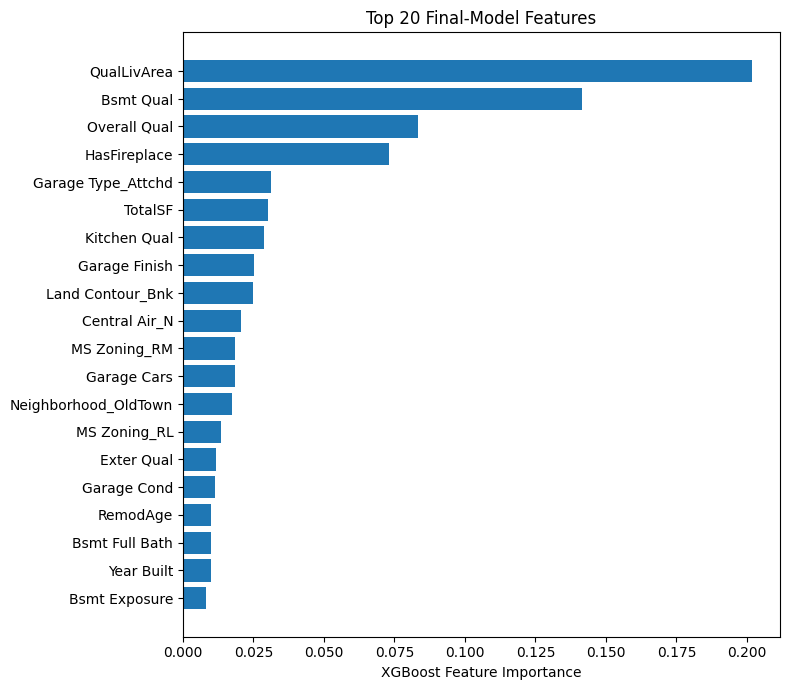

In [15]:
preprocessor=final_model.named_steps["preprocessor"]
xgb=final_model.named_steps["model"]

feature_names=preprocessor.get_feature_names_out()
feature_names=np.array([
    n.replace("numeric__","").replace("ordinal__","").replace("nominal__","")
    for n in feature_names
])

importance=pd.DataFrame({
    "Feature":feature_names,
    "Importance":xgb.feature_importances_
}).sort_values("Importance",ascending=False)

display(importance.head(20).round(5))
importance.to_csv(PROCESSED_DIR/"xgboost_feature_importance.csv",index=False)

top=importance.head(20).sort_values("Importance")
plt.figure(figsize=(8,7))
plt.barh(top["Feature"],top["Importance"])
plt.xlabel("XGBoost Feature Importance")
plt.title("Top 20 Final-Model Features")
plt.tight_layout()
plt.savefig(FIGURES_DIR/"xgboost_top20_feature_importance.png",dpi=300,bbox_inches="tight")
plt.show()


## 11. SHAP global interpretation

SHAP decomposes model predictions into feature contributions. To keep the analysis computationally manageable, SHAP is calculated on a reproducible sample of up to 300 test observations.

The test sample is used only for **post-hoc interpretation after final model evaluation**, not for model selection.


In [16]:
X_test_transformed=preprocessor.transform(X_test)

rng=np.random.default_rng(SEED)
sample_n=min(300,X_test_transformed.shape[0])
sample_pos=np.sort(rng.choice(X_test_transformed.shape[0],size=sample_n,replace=False))
X_shap=X_test_transformed[sample_pos]

# Convert sparse matrix if necessary for SHAP/plotting.
if hasattr(X_shap,"toarray"):
    X_shap_dense=X_shap.toarray()
else:
    X_shap_dense=np.asarray(X_shap)

explainer=shap.TreeExplainer(xgb)
shap_values=explainer.shap_values(X_shap_dense)

mean_abs_shap=np.abs(shap_values).mean(axis=0)
shap_importance=pd.DataFrame({
    "Feature":feature_names,
    "MeanAbsSHAP":mean_abs_shap
}).sort_values("MeanAbsSHAP",ascending=False)

display(shap_importance.head(20).round(2))
shap_importance.to_csv(PROCESSED_DIR/"shap_global_importance.csv",index=False)


,Feature,MeanAbsSHAP
45,QualLivArea,27895.730469
38,TotalSF,6894.770020
3,Overall Qual,5776.680176
5,Year Built,3682.010010
8,BsmtFin SF 1,3263.669922
4,Overall Cond,3254.780029
2,Lot Area,2885.600098
51,Kitchen Qual,2607.610107
36,HouseAge,2349.719971
48,Bsmt Qual,2014.380005


/tmp/ipykernel_2842/3649714242.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


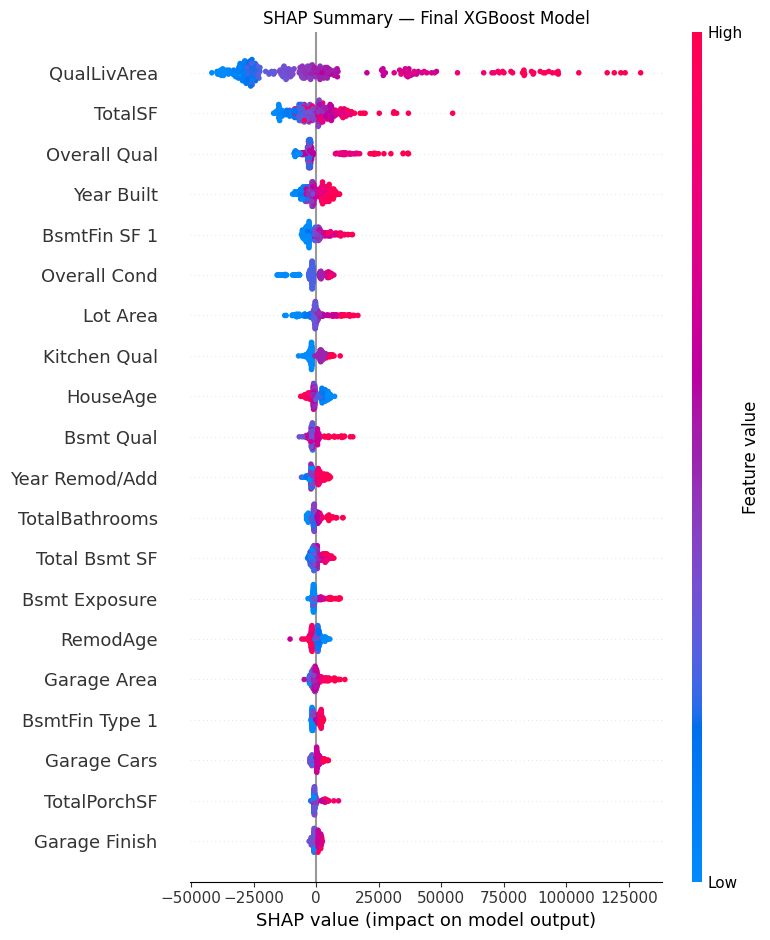

In [17]:
shap.summary_plot(
    shap_values,
    X_shap_dense,
    feature_names=feature_names,
    show=False,
    max_display=20
)
plt.title("SHAP Summary — Final XGBoost Model")
plt.tight_layout()
plt.savefig(FIGURES_DIR/"shap_summary.png",dpi=300,bbox_inches="tight")
plt.show()


## 11.1 SHAP dependence for influential features

Global SHAP magnitude tells us **which** features matter. Dependence plots add information about **how feature values are associated with positive or negative contributions** to predictions.

These plots are interpretive rather than causal: they describe the fitted model's behaviour and should not be read as proving that changing a property characteristic would cause the corresponding price change.


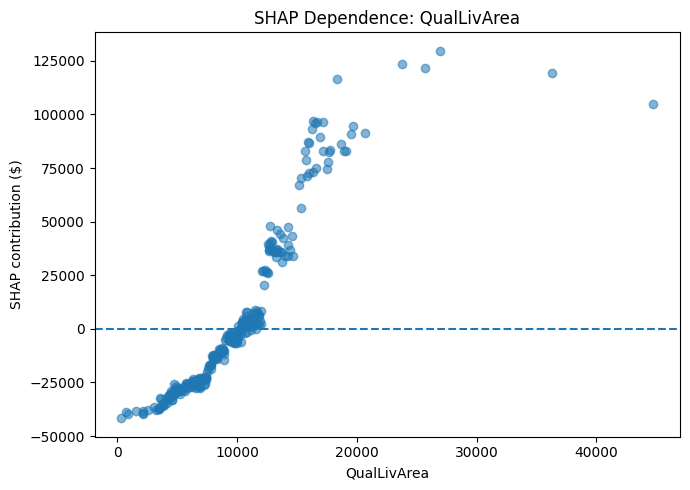

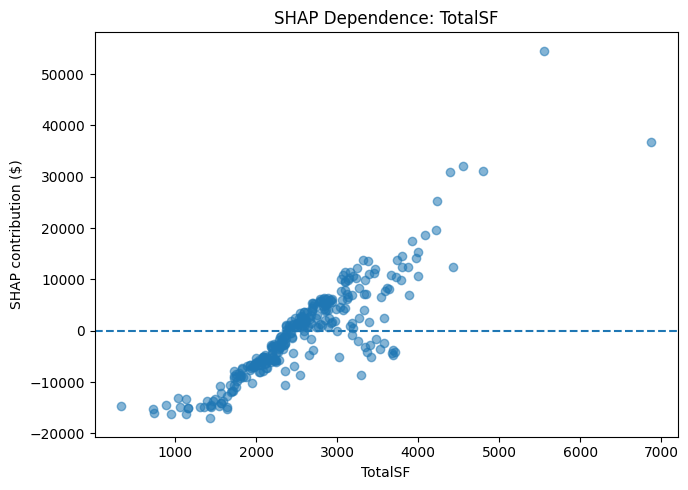

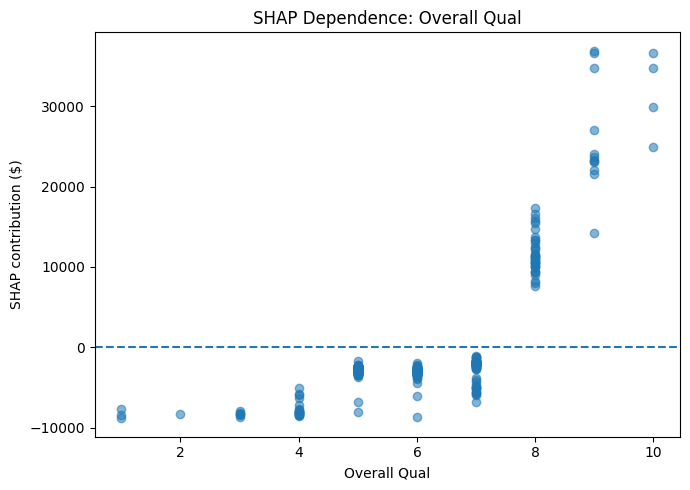

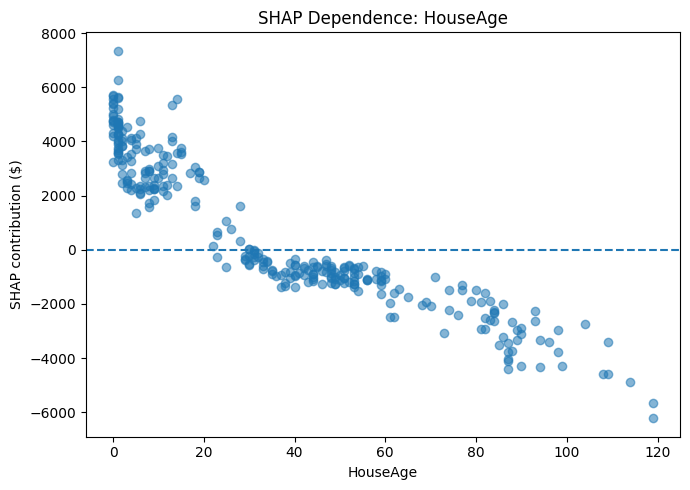

In [18]:
dependence_candidates=["QualLivArea","TotalSF","Overall Qual","HouseAge"]
for feature in dependence_candidates:
    matches=np.where(feature_names==feature)[0]
    if len(matches)==0:
        print("Feature not found:",feature)
        continue
    j=int(matches[0])
    plt.figure(figsize=(7,5))
    plt.scatter(X_shap_dense[:,j],shap_values[:,j],alpha=0.55)
    plt.axhline(0,linestyle="--")
    plt.xlabel(feature)
    plt.ylabel("SHAP contribution ($)")
    plt.title(f"SHAP Dependence: {feature}")
    plt.tight_layout()
    safe=feature.lower().replace(" ","_").replace("/","_")
    plt.savefig(FIGURES_DIR/f"shap_dependence_{safe}.png",dpi=300,bbox_inches="tight")
    plt.show()


## 12. SHAP local explanations

We inspect three representative test predictions:
- the lowest absolute-error prediction;
- a prediction near the median absolute error;
- the highest absolute-error prediction.

This demonstrates how feature effects vary across individual properties, directly supporting RQ4.


In [19]:
# SHAP for all test rows to obtain exact local examples.
if hasattr(X_test_transformed,"toarray"):
    X_test_dense=X_test_transformed.toarray()
else:
    X_test_dense=np.asarray(X_test_transformed)

all_shap=explainer.shap_values(X_test_dense)
base=float(np.asarray(explainer.expected_value).reshape(-1)[0])

order=np.argsort(abs_error)
example_positions={
    "Low error":int(order[0]),
    "Median error":int(order[len(order)//2]),
    "High error":int(order[-1])
}

local_rows=[]
for label,pos in example_positions.items():
    contributions=pd.DataFrame({
        "Feature":feature_names,
        "SHAP":all_shap[pos]
    })
    contributions["AbsSHAP"]=contributions["SHAP"].abs()
    contributions=contributions.nlargest(10,"AbsSHAP")

    print("\n",label)
    print(f"Actual: ${y_test.iloc[pos]:,.0f}")
    print(f"Predicted: ${test_pred[pos]:,.0f}")
    display(contributions[["Feature","SHAP"]].round(2))

    for _,r in contributions.iterrows():
        local_rows.append({
            "Example":label,
            "TestPosition":pos,
            "Actual":y_test.iloc[pos],
            "Predicted":test_pred[pos],
            "Feature":r["Feature"],
            "SHAP":r["SHAP"]
        })

pd.DataFrame(local_rows).to_csv(
    PROCESSED_DIR/"shap_local_examples.csv",index=False
)



 Low error
Actual: $105,000
Predicted: $104,970


,Feature,SHAP
45,QualLivArea,-35735.789062
38,TotalSF,-14076.040039
3,Overall Qual,-8248.259766
4,Overall Cond,5415.750000
5,Year Built,-4602.490234
36,HouseAge,-3095.189941
8,BsmtFin SF 1,-2479.620117
11,Total Bsmt SF,-2277.620117
51,Kitchen Qual,-2210.939941
61,Paved Drive,-1931.810059



 Median error
Actual: $214,000
Predicted: $205,290


,Feature,SHAP
38,TotalSF,10097.650391
45,QualLivArea,5776.089844
8,BsmtFin SF 1,-5400.009766
5,Year Built,5120.109863
36,HouseAge,4285.859863
51,Kitchen Qual,3874.689941
11,Total Bsmt SF,3088.250000
4,Overall Cond,-2663.189941
57,BsmtFin Type 1,1958.140015
3,Overall Qual,-1869.569946



 High error
Actual: $745,000
Predicted: $378,600


,Feature,SHAP
45,QualLivArea,105010.546875
1,Lot Frontage,-54791.078125
38,TotalSF,36864.968750
3,Overall Qual,29856.980469
247,Sale Condition_Abnorml,-9687.570312
51,Kitchen Qual,9581.490234
8,BsmtFin SF 1,9494.530273
13,2nd Flr SF,9367.929688
2,Lot Area,8034.970215
23,Fireplaces,6554.160156


## 13. Final evidence summary


In [20]:
print("FINAL HELD-OUT TEST PERFORMANCE")
print("--------------------------------")
print(f"MAE:  ${final_metrics['MAE']:,.2f}")
print(f"RMSE: ${final_metrics['RMSE']:,.2f}")
print(f"R²:   {final_metrics['R2']:.4f}")

print("\nTOP 10 FEATURES BY MEAN |SHAP|")
display(shap_importance.head(10).round(2))

print("\nERROR BY PRICE QUARTILE")
display(quartile_errors.round(2))


FINAL HELD-OUT TEST PERFORMANCE
--------------------------------
MAE:  $13,885.15
RMSE: $25,354.31
R²:   0.8999

TOP 10 FEATURES BY MEAN |SHAP|


,Feature,MeanAbsSHAP
45,QualLivArea,27895.730469
38,TotalSF,6894.770020
3,Overall Qual,5776.680176
5,Year Built,3682.010010
8,BsmtFin SF 1,3263.669922
4,Overall Cond,3254.780029
2,Lot Area,2885.600098
51,Kitchen Qual,2607.610107
36,HouseAge,2349.719971
48,Bsmt Qual,2014.380005



ERROR BY PRICE QUARTILE


,n,ActualMedian,MAE,RMSE,MeanResidual
PriceQuartile,,,,,
Q1 lowest,147,108000.0,11663.94,16697.29,-7460.30
Q2,150,145050.0,8747.11,12226.74,-327.45
Q3,143,184750.0,10659.59,15114.83,-1921.97
Q4 highest,146,264763.5,24559.67,43841.87,7582.61


## Notebook 05 Conclusions

This notebook preserves the frozen final evaluation and strengthens its interpretation.

- Final held-out metrics remain the project's primary generalisation estimates.
- Bootstrap 95% intervals quantify uncertainty without retuning the model.
- Residual and subgroup analyses show where errors are concentrated, including price, neighborhood, quality, age and living-area groups.
- Global SHAP identifies influential features; dependence plots describe how influential feature values relate to model contributions.
- Local SHAP examples demonstrate that contributions vary between individual properties.
- SHAP and subgroup patterns are **descriptive model interpretations, not causal effects**.

The held-out test set has now served its intended purpose. No subsequent sensitivity experiment should be used to replace the frozen final model based on these 586 observations.
